In [1]:
# MODULOS Y DATOS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Redes Neuronales: Keras
from keras.models import Sequential
from keras.layers import  Dense

# Dataset
dataset = pd.read_csv('https://raw.githubusercontent.com/cvva/Datasets/refs/heads/master/pima-indians-diabetes.csv',
        header=None)
dataset

,0,1,2,3,4,5,6,7,8
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


"pregnant"	"glucose"	"pressure"	"triceps"	"insulin"	"mass"	"pedigree"	"age"	"diabetes"

In [2]:
# Dataset
dataset = pd.read_csv('https://raw.githubusercontent.com/cvva/Datasets/refs/heads/master/pima-indians-diabetes.csv',
        header=None, names=["pregnant","glucose","pressure","triceps","insulin","mass","pedigree","age","diabetes"])
dataset

,pregnant,glucose,pressure,triceps,insulin,mass,pedigree,age,diabetes
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [3]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   pregnant  768 non-null    int64  
 1   glucose   768 non-null    int64  
 2   pressure  768 non-null    int64  
 3   triceps   768 non-null    int64  
 4   insulin   768 non-null    int64  
 5   mass      768 non-null    float64
 6   pedigree  768 non-null    float64
 7   age       768 non-null    int64  
 8   diabetes  768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
# Necesitamos definir el objeto donde se encontraran las variables independientes (X)
# y la variblae dependiente (y)
X = dataset.iloc[:,0:8]  # varibles independientes (predictores)
y = dataset.iloc[:,8] # variable dependiente (predecir)

print(f'Numero de variables independientes: {X.shape[1]}')
# print("Numero de variables independientes: %d" %(X.shape[1]))
print(f'Numero de niveles de la variable dependiente y : {y.unique()}')
print('Distribucion de y\n', y.value_counts())


Numero de variables independientes: 8
Numero de niveles de la variable dependiente y : [1 0]
Distribucion de y
 diabetes
0    500
1    268
Name: count, dtype: int64


### Diseño de nuestra primera red neuronal

In [5]:
# creacion de un modelo: instancia de la clase Secuential
model_1 = Sequential()

# primera capa oculta
model_1.add(Dense(
    units=6,
    activation='relu',
    input_dim=8,
    name='PrimeraCapaOculta_CapaEntrada' 
))
# agregar otras 4 capas ocualtas
model_1.add(Dense(
    units=25,
    activation='tanh',
    name='SegundaCapaOculta' 
))

model_1.add(Dense(
    units=35,
    activation='exponential',
    name='TerceraCapaOculta' 
))

model_1.add(Dense(
    units=12,
    activation='elu',
    name='CuartaCapaOculta' 
))

model_1.add(Dense(
    units=5,
    activation='softsign',
    name='QuintaCapaOculta' 
))

# agregamos la capa de salida
model_1.add(Dense(
    units = 1,
    activation = 'sigmoid',
    name = 'CapaSalida'
))

c:\Users\Instructor\Desktop\ingswsenati\entorno\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### Metodo mas basico y rapido de visualizacion de la red neuronal

In [6]:
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ PrimeraCapaOculta_CapaEntrada   │ (None, 6)              │            54 │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ SegundaCapaOculta (Dense)       │ (None, 25)             │           175 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ TerceraCapaOculta (Dense)       │ (None, 35)             │           910 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CuartaCapaOculta (Dense)        │ (None, 12)             │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ QuintaCapaOculta (Dense)        │ (None, 5)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CapaSalida (Dense)              │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,642 (6.41 KB)

 Trainable params: 1,642 (6.41 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# get_config(): configuracion de la red neuronal en formato JSON
model_1.get_config()

{'name': 'sequential',
 'trainable': True,
 'dtype': {'module': 'keras',
  'class_name': 'DTypePolicy',
  'config': {'name': 'float32'},
  'registered_name': None},
 'layers': [{'module': 'keras.layers',
   'class_name': 'InputLayer',
   'config': {'batch_shape': (None, 8),
    'dtype': 'float32',
    'sparse': False,
    'ragged': False,
    'name': 'input_layer',
    'optional': False},
   'registered_name': None},
  {'module': 'keras.layers',
   'class_name': 'Dense',
   'config': {'name': 'PrimeraCapaOculta_CapaEntrada',
    'trainable': True,
    'dtype': {'module': 'keras',
     'class_name': 'DTypePolicy',
     'config': {'name': 'float32'},
     'registered_name': None},
    'units': 6,
    'activation': 'relu',
    'use_bias': True,
    'kernel_initializer': {'module': 'keras.initializers',
     'class_name': 'GlorotUniform',
     'config': {'seed': None, 'input_axes': None, 'output_axes': None},
     'registered_name': None},
    'bias_initializer': {'module': 'keras.initiali

#### Observemos nuestra arquitectura (red neuronal) en un objeto grafico

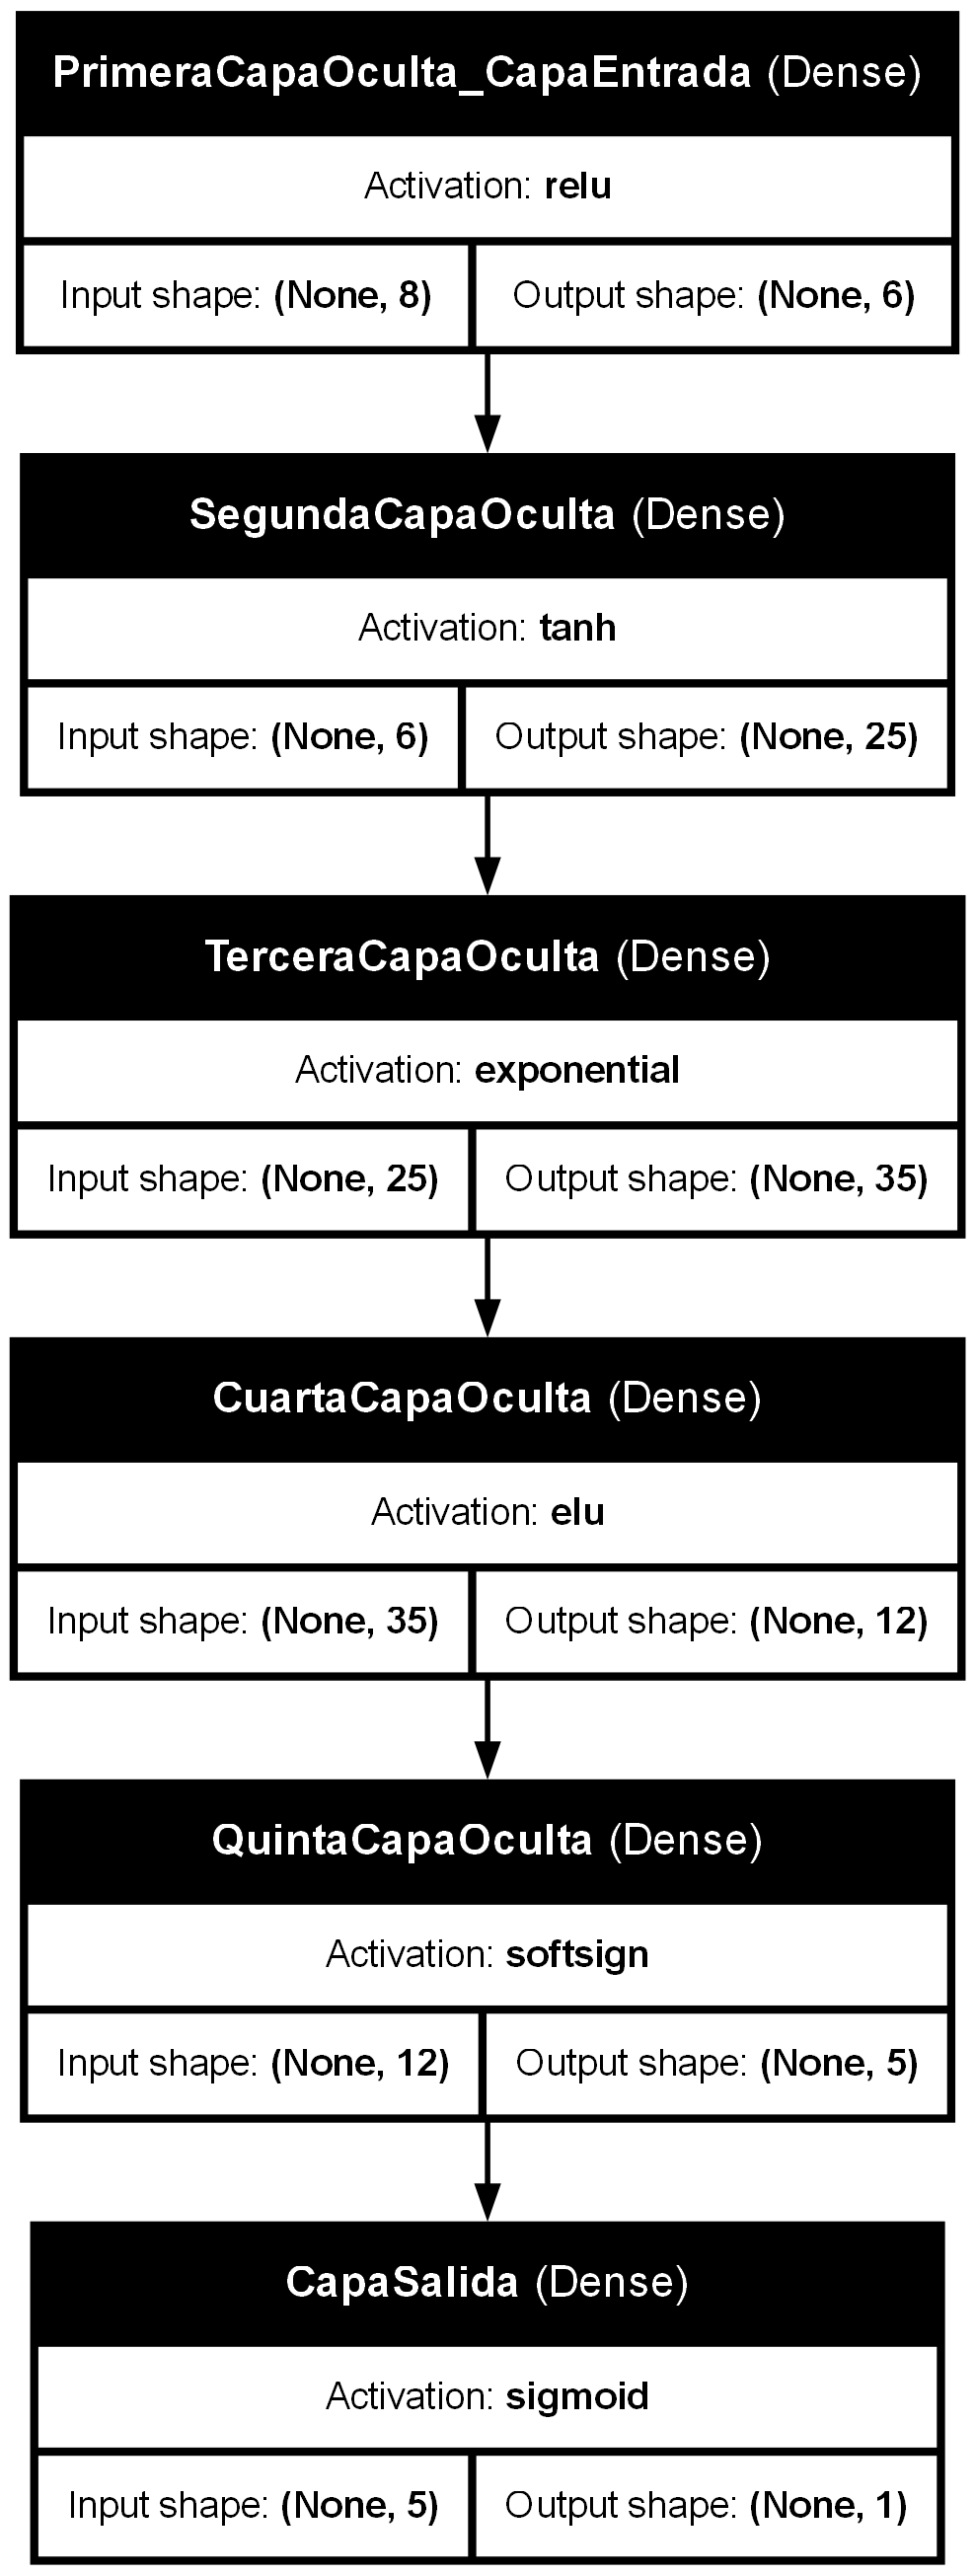

In [8]:
import os
os.environ["PATH"] += os.pathsep + r'C:\Program Files\Graphviz\bin'

from keras.utils import plot_model

plot_model(
    model_1,
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=True
)

In [9]:
# funciones de activaciones que prevee el submodulo activations
from keras import activations
dir(activations)

['__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 'celu',
 'deserialize',
 'elu',
 'exponential',
 'gelu',
 'get',
 'glu',
 'hard_shrink',
 'hard_sigmoid',
 'hard_silu',
 'hard_swish',
 'hard_tanh',
 'leaky_relu',
 'linear',
 'log_sigmoid',
 'log_softmax',
 'mish',
 'relu',
 'relu6',
 'selu',
 'serialize',
 'sigmoid',
 'silu',
 'soft_shrink',
 'softmax',
 'softplus',
 'softsign',
 'sparse_plus',
 'sparse_sigmoid',
 'sparsemax',
 'squareplus',
 'swish',
 'tanh',
 'tanh_shrink',
 'threshold']

'celu',
 'deserialize',
 'elu',
 'exponential',
 'gelu',
 'get',
 'glu',
 'hard_shrink',
 'hard_sigmoid',
 'hard_silu',
 'hard_swish',
 'hard_tanh',
 'leaky_relu',
 'linear',
 'log_sigmoid',
 'log_softmax',
 'mish',
 'relu',
 'relu6',
 'selu',
 'serialize',
 'sigmoid',
 'silu',
 'soft_shrink',
 'softmax',
 'softplus',
 'softsign',
 'sparse_plus',
 'sparse_sigmoid',
 'sparsemax',
 'squareplus',
 'swish',
 'tanh',
 'tanh_shrink',
 'threshold'

In [10]:
help(activations.tanh)

Help on function tanh in module keras.src.activations.activations:

tanh(x)
    Hyperbolic tangent activation function.

    It is defined as:
    `tanh(x) = sinh(x) / cosh(x)`, i.e.
    `tanh(x) = ((exp(x) - exp(-x)) / (exp(x) + exp(-x)))`.

    Args:
        x: Input tensor.



In [11]:
# compilacion de nuestra arquitectura de red neuronal
model_1.compile(
    loss='binary_crossentropy',
    optimizer='Adam',
    metrics=['accuracy', 'AUC']
)
# lista de funcion de perdida que provee keras
# https://keras.io/api/losses/

# lista de optimizadores que provee keras
# https://keras.io/api/optimizers/

# Lista de metricas que provee keras
# https://keras.io/api/metrics/

In [12]:
# ajustamos los datos a la arquitectura de nuestra primera red neuronal
model_1.fit(X, y, epochs=1000)

Epoch 1/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - AUC: 0.5662 - accuracy: 0.6406 - loss: 0.6446   
Epoch 2/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.5857 - accuracy: 0.6523 - loss: 0.6387 
Epoch 3/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.6143 - accuracy: 0.6589 - loss: 0.6280 
Epoch 4/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.6262 - accuracy: 0.6589 - loss: 0.6254 
Epoch 5/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.6195 - accuracy: 0.6562 - loss: 0.6269 
Epoch 6/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.6144 - accuracy: 0.6536 - loss: 0.6260 
Epoch 7/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.6326 - accuracy: 0.6562 - loss: 0.6216 
Epoch 8/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.6348 - accuracy: 0.6602 - loss: 0.6212 
Epoch 9/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.6441 - accuracy: 0.6680 - loss: 0.6185 
Epoch 10/1000
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.6308 - accuracy: 0.6654 - l

In [13]:
type(model_1)

keras.src.models.sequential.Sequential

In [14]:
dir(model_1)

['__call__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_add_trackable_child',
 '_add_variable_with_custom_getter',
 '_aggregate_additional_loss',
 '_allow_non_tensor_positional_args',
 '_api_export_path',
 '_api_export_symbol_id',
 '_assert_compile_called',
 '_assert_input_compatibility',
 '_assign_variable_values',
 '_auto_config',
 '_autoconvert_optionals',
 '_build_at_init',
 '_build_by_run_for_kwargs',
 '_build_by_run_for_single_pos_arg',
 '_build_from_call_spec',
 '_build_shapes_dict',
 '_calibration_capture',
 '_call_context_args',
 '_call_has_context_arg',
 '_call_has_mask_arg',
 '_call_has_tr

'activity_regularizer',
 'add',
 'add_loss',
 'add_metric',
 'add_variable',
 'add_weight',
 'autocast',
 'build',
 'build_from_config',
 'built',
 'call',
 'call_signature_parameters',
 'compile',
 'compile_from_config',
 'compiled',
 'compiled_loss',
 'compiled_metrics',
 'compute_dtype',
 'compute_loss',
 'compute_mask',
 'compute_metrics',
 'compute_output_shape',
 'compute_output_spec',
 'count_params',
 'distribute_reduction_method',
 'distribute_strategy',
 'dtype',
 'dtype_policy',
 'evaluate',
 'export',
 'fit',
 'from_config',
 'get_build_config',
 'get_compile_config',
 'get_config',
 'get_layer',
 'get_metrics_result',
 'get_quantization_layer_structure',
 'get_state_tree',
 'get_weights',
 'history',
 'input',
 'input_dtype',
 'input_shape',
 'input_spec',
 'inputs',
 'jit_compile',
 'layers',
 'load_own_variables',
 'load_weights',
 'lora_enabled',
 'loss',
 'losses',
 'make_predict_function',
 'make_test_function',
 'make_train_function',
 'metrics',
 'metrics_names',
 'metrics_variables',
 'name',
 'non_trainable_variables',
 'non_trainable_weights',
 'optimizer',
 'output',
 'output_shape',
 'outputs',
 'path',
 'pop',
 'predict',
 'predict_function',
 'predict_on_batch',
 'predict_step',
 'quantization_config',
 'quantization_mode',
 'quantization_summary',
 'quantize',
 'quantized_build',
 'quantized_call',
 'rematerialized_call',
 'reset_metrics',
 'run_eagerly',
 'save',
 'save_own_variables',
 'save_weights',
 'set_state_tree',
 'set_weights',
 'stateless_call',
 'stateless_compute_loss',
 'steps_per_execution',
 'stop_training',
 'summary',
 'supports_jit',
 'supports_masking',
 'symbolic_call',
 'test_function',
 'test_on_batch',
 'test_step',
 'to_json',
 'train_function',
 'train_on_batch',
 'train_step',
 'trainable',
 'trainable_variables',
 'trainable_weights',
 'unrolled_steps_per_execution',
 'variable_dtype',
 'variable_serialization_spec',
 'variables',
 'weights'

In [15]:
model_1.layers

[<Dense name=PrimeraCapaOculta_CapaEntrada, built=True>,
 <Dense name=SegundaCapaOculta, built=True>,
 <Dense name=TerceraCapaOculta, built=True>,
 <Dense name=CuartaCapaOculta, built=True>,
 <Dense name=QuintaCapaOculta, built=True>,
 <Dense name=CapaSalida, built=True>]

In [16]:
# primera capa oculta
model_1.layers[0]

<Dense name=PrimeraCapaOculta_CapaEntrada, built=True>

In [17]:
# matriz de pesos de la primera capa oculta
model_1.layers[0].weights

[<Variable path=sequential/PrimeraCapaOculta_CapaEntrada/kernel, shape=(8, 6), dtype=float32, value=[[ 1.2594499e-01  7.9523462e-01 -8.3380109e-01  2.8532311e-02
    3.7148210e-01  8.5082836e-02]
  [ 2.3044719e-01  3.0190552e-02 -2.0738362e-01 -1.2069371e-01
    3.9766124e-01  5.3444368e-01]
  [ 3.0166075e-01  3.0366856e-01  4.3684644e-01 -4.4413671e-01
   -6.8993658e-01 -8.0483034e-02]
  [-9.4915979e-02 -2.8680566e-01 -1.6197701e-01  3.8067734e-01
    2.2153930e-01  2.8474626e-01]
  [ 3.4218952e-01 -1.9887879e-01  1.8173322e-01  2.5582150e-01
   -3.8601387e-01  1.0348807e-02]
  [ 5.0712603e-01 -5.6152987e-01  1.9641683e-01  1.4510809e-01
    1.8778375e-01 -6.0923022e-01]
  [ 1.7582706e+00  6.9814044e-01 -2.5295672e+00  2.7868709e-01
   -8.1802255e-01 -9.6308923e-01]
  [ 1.3318825e-01  6.5424323e-01 -7.6910394e-04  5.0474340e-01
   -3.8937739e-01 -2.6509783e-01]]>,
 <Variable path=sequential/PrimeraCapaOculta_CapaEntrada/bias, shape=(6,), dtype=float32, value=[-1.0998874   0.18105553  

In [18]:
# matriz de pesos de la segunda capa oculta
model_1.layers[1].weights

[<Variable path=sequential/SegundaCapaOculta/kernel, shape=(6, 25), dtype=float32, value=[[-0.34160972 -0.28820205  0.3366881  -0.3431263  -0.13810994  0.25582618
   -0.32756507 -0.2667491  -0.1488155  -0.1115984  -0.05807734  0.22377454
   -0.4234148   0.33716658  0.08474696 -0.2754208   0.15294103 -0.05079263
   -0.2350315   0.08123466  0.08926222  0.19151615  0.20843552  0.10507674
    0.10177478]
  [-0.22484398 -0.43947825  0.34837943 -0.01738554  0.41284016  0.32948038
   -0.3024121  -0.3456345  -0.13427801  0.34864497 -0.49229082  0.12457277
   -0.35984617  0.3694212  -0.01552218  0.29675075 -0.04216292 -0.3549495
   -0.08213809 -0.2449592  -0.12515055 -0.41995934  0.02755323  0.34222555
    0.1379773 ]
  [-0.23034862 -0.38214025  0.10676509 -0.4539437   0.08680917 -0.5123272
    0.19958673  0.1070245   0.34714124 -0.3647252  -1.1284744  -0.4211995
    0.34321237 -0.30913052 -0.11936654 -0.41358706 -0.0599113  -0.1227551
   -0.38638565  0.6547633   0.28834876  0.45824367 -0.26292

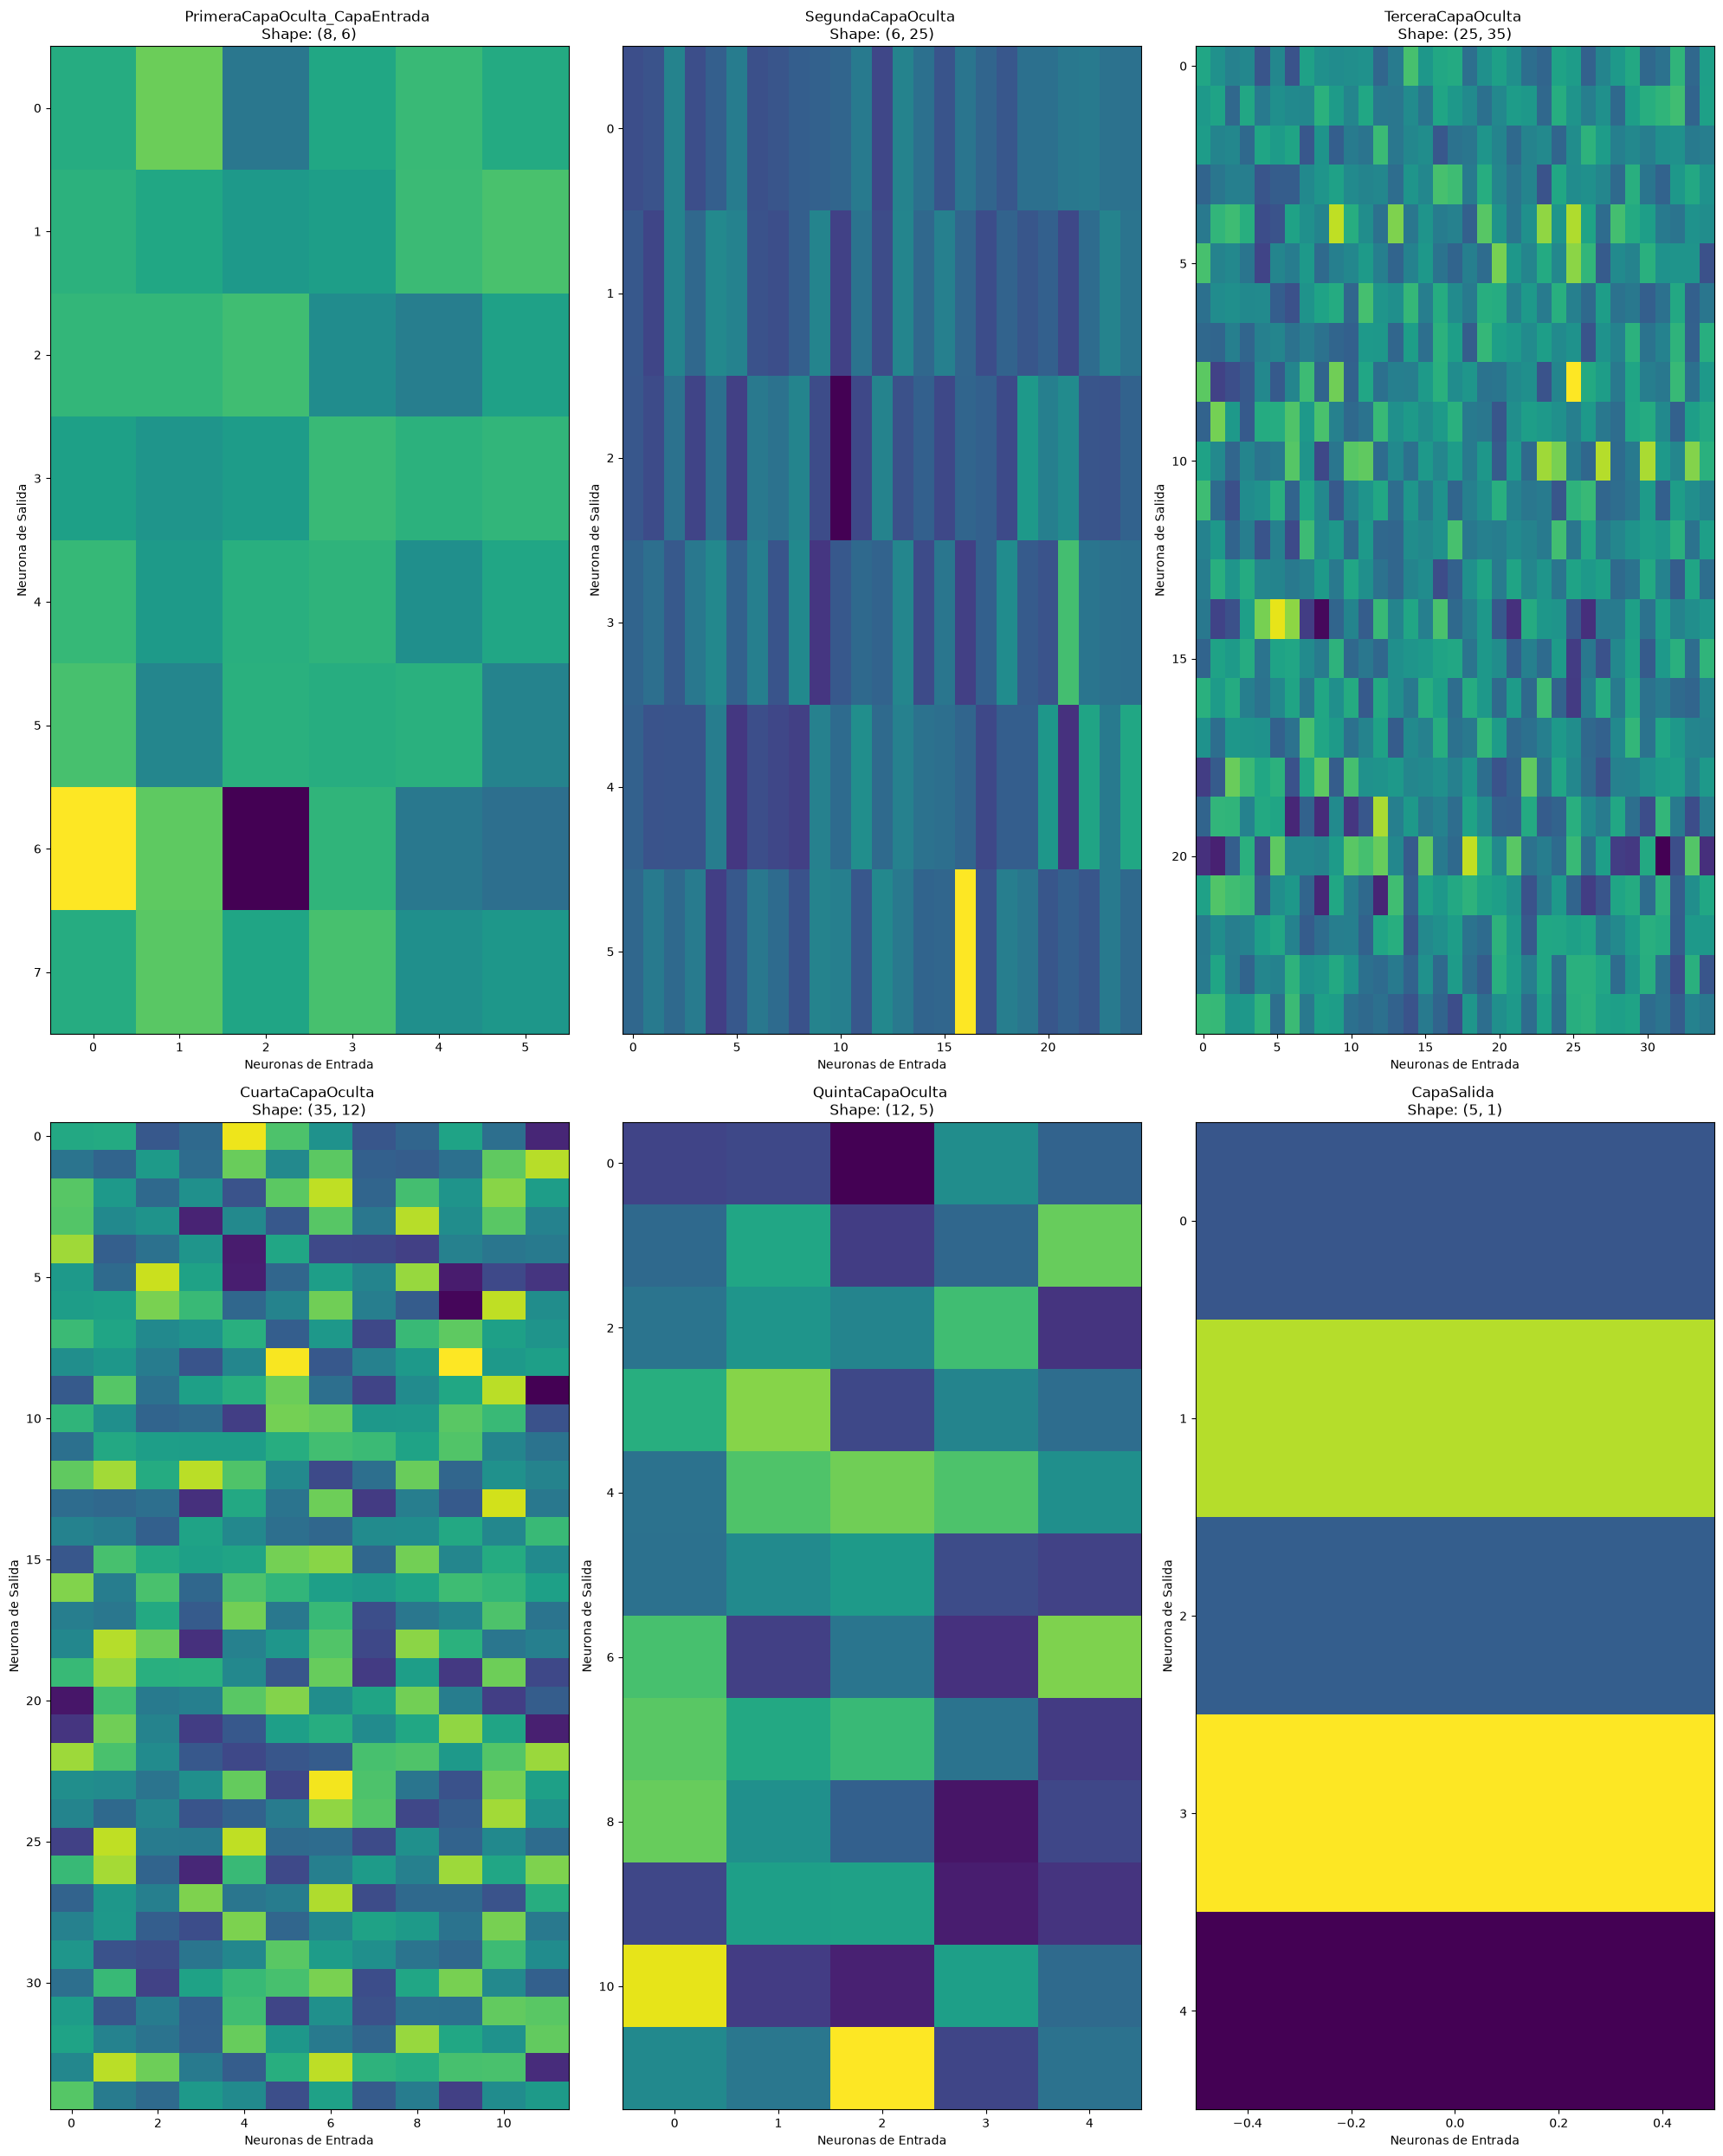

In [20]:
# Visualizacion de las matrices de pesos : Heatmap
def plot_weight_heatmaps(model, figsize = (20, 25)):
    #calcular el numero de capas
    n_dense_layers = sum(1 for layer in model.layers if isinstance(layer, Dense))
    #contruir nuestra matriz de graficos (heapmat)
    fig, axes = plt.subplots(nrows=2, ncols=(n_dense_layers + 1)//2, figsize = figsize)
    axes = axes.flatten()

    #graficamos cada heatmap en su lugar correspondiente
    ax_idx = 0
    for layer in model.layers:
        if isinstance(layer, Dense) and hasattr(layer, 'weights'):
            weights = layer.weights[0].numpy()

            if weights.ndim == 2:
                im = axes[ax_idx].imshow(weights, cmap = 'viridis', aspect = 'auto')
                # agregar etiquetas
                axes[ax_idx].set_title(f"{layer.name} \nShape: {weights.shape}")
                axes[ax_idx].set_xlabel("Neuronas de Entrada")
                axes[ax_idx].set_ylabel("Neurona de Salida")
                
                ax_idx = ax_idx + 1

    plt.tight_layout()
    plt.show()

plot_weight_heatmaps(model_1)

In [22]:
model_1.metrics_names

['loss', 'compile_metrics']

In [27]:
# model_1.fit(X, y, epochs=1000)
presicion = model_1.evaluate(X,y)[1]
auc = model_1.evaluate(X,y)[2]

print("""
Presicion : %f
AUC : %f
""" %(presicion, auc))

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.8942 - accuracy: 0.8242 - loss: 0.3829 
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - AUC: 0.8942 - accuracy: 0.8242 - loss: 0.3829 

Presicion : 0.824219
AUC : 0.894175



### Analisis

- No hemos construido datos de entrenamiento (que usualmente se utilizan para calcular los parametros del modelo) ni de testeo (que usualmente se utiliza para evaluar el modelo)
- Consecuancia a esto es que nuestro modelo no esta generalizando conocimiento si no memorizandolo
- para este modelo en particular (model_1) tenemos mas parametros del modelo que observaciones (tamaño de muestra)
- Analizar la complejidad del modelo para lograr los mismos indicadores de calidad pero con modelos menos complejos (numero de capas ocultas y numero de neuronas en cada capa oculta)